# 8. 추가 실험: 공휴일 피처

서울시 따릉이 일별 수요 예측. [요구사항](../../docs/ml/REQUIREMENTS.md).

In [1]:
from pathlib import Path
import sys, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from src.ml.features import FEATURES, load_daily, make_features
from src.ml.splits import split_data, time_cv
from src.ml.models import model_candidates
from src.ml.evaluation import metrics, compare, grouped_metrics
from src.ml.tuning import tune_models
from src.ml.predict import forecast
from sklearn.base import clone
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.figsize": (10, 4), "font.family": "Malgun Gothic", "axes.unicode_minus": False})
OUT = ROOT / "outputs/ml"
OUT.mkdir(parents=True, exist_ok=True)
LOCAL = ROOT / "data/processed"
LOCAL.mkdir(parents=True, exist_ok=True)
daily = load_daily(ROOT)
frame = make_features(daily)
train, validation, final_train, test = split_data(frame)


In [2]:
from src.ml.calendar_features import HOLIDAY_FEATURES, add_holiday, holiday_table

holiday_frame = add_holiday(frame)
train8, validation8, final_train8, test8 = split_data(holiday_frame)
listing = holiday_table(daily.date.min(), daily.date.max())
listing["weekday"] = listing.date.dt.day_name()
listing.to_csv(OUT / "08_holidays.csv", index=False)
counts = pd.DataFrame([{"split": name, "rows": len(part), "holidays": int(part.holiday.sum()),
                        "weekday_holidays": int(((part.holiday == 1) & (part.weekend == 0)).sum())}
                       for name, part in [("train", train8), ("validation", validation8),
                                          ("final_train", final_train8), ("test", test8)]])
counts.to_csv(OUT / "08_holiday_counts.csv", index=False)
display(listing)
display(counts)


,date,name,weekday
0,2025-01-01,신정연휴,Wednesday
1,2025-01-27,임시공휴일,Monday
2,2025-01-28,설날 전날,Tuesday
3,2025-01-29,설날,Wednesday
4,2025-01-30,설날 다음날,Thursday
5,2025-03-01,삼일절,Saturday
6,2025-03-03,삼일절 대체 휴일,Monday
7,2025-05-05,부처님오신날; 어린이날,Monday
8,2025-05-06,부처님오신날 대체 휴일; 어린이날 대체 휴일,Tuesday
9,2025-06-03,대통령 선거일,Tuesday


,split,rows,holidays,weekday_holidays
0,train,243,8,7
1,validation,92,7,6
2,final_train,335,15,13
3,test,181,12,9


- 대체·임시·선거 공휴일을 포함한 공식 공휴일을 holiday 피처로 추가함(holidays 패키지 KR).
- 평일 공휴일은 학습 7일, 테스트 9일로 표본이 매우 적음.
- 공휴일은 사전에 공표되어 D-1 00:00에 사용할 수 있으며 대여건수와 무관하게 생성됨.
- 노동절은 2026년부터 공휴일이며 2025-05-01은 공휴일이 아니어서 두 해의 정의가 다름.

In [3]:
# Pre-registered rule: adopt the holiday feature only if the selected model's mean CV MAE on the training period improves.
experiments, rows = {}, []
for name, columns in [("base", FEATURES), ("holiday", HOLIDAY_FEATURES)]:
    searches, _, _, selected = tune_models(train8[columns], train8.rentals)
    experiments[name] = {"columns": columns, "search": searches[selected], "model": selected}
    for model_name, search in searches.items():
        rows.append({"features": name, "model": model_name, "selected": model_name == selected,
                     "params": str(search.best_params_), "cv_MAE": -search.best_score_,
                     "cv_std": search.cv_results_["std_test_score"][search.best_index_]})
cv8 = pd.DataFrame(rows)
cv8.to_csv(OUT / "08_cv.csv", index=False)
display(cv8.round(3))
base_cv, holiday_cv = (-experiments[name]["search"].best_score_ for name in ("base", "holiday"))
decision = {"rule": "adopt holiday feature if selected-model mean CV MAE decreases; test is report-only",
            "base_model": experiments["base"]["model"], "base_cv_MAE": base_cv,
            "holiday_model": experiments["holiday"]["model"], "holiday_cv_MAE": holiday_cv,
            "cv_change_pct": (holiday_cv / base_cv - 1) * 100, "adopt_holiday": bool(holiday_cv < base_cv)}
display(decision)


,features,model,selected,params,cv_MAE,cv_std
0,base,ridge,False,{'ridge__alpha': 100},32550.088,6792.961
1,base,random_forest,True,"{'randomforestregressor__max_depth': 3, 'rando...",29886.893,5212.626
2,holiday,ridge,False,{'ridge__alpha': 100},32209.840,6717.871
3,holiday,random_forest,True,"{'randomforestregressor__max_depth': 3, 'rando...",29923.713,5212.956


{'rule': 'adopt holiday feature if selected-model mean CV MAE decreases; test is report-only',
 'base_model': 'random_forest',
 'base_cv_MAE': np.float64(29886.893129104257),
 'holiday_model': 'random_forest',
 'holiday_cv_MAE': np.float64(29923.712894620632),
 'cv_change_pct': np.float64(0.12319703275052163),
 'adopt_holiday': False}

- 기존 피처의 선정 모델 random_forest CV MAE 29,887건은 5번 결과와 같은 조건임.
- Ridge는 공휴일 추가로 CV MAE가 -1.05% 변해 선형 모델은 공휴일 신호를 일부 활용한 것으로 보임.
- 얕은 Random Forest(max_depth=3, min_samples_leaf=7)는 적은 공휴일 표본으로 분기를 만들기 어려웠을 가능성이 있음.
- 공휴일 추가 후 선정 모델 random_forest의 CV MAE는 29,924건으로 +0.12% 변함.
- 사전에 정한 CV 기준에 따라 공휴일 피처를 채택하지 않음.
- fold 표준편차 5,213건 대비 차이 37건으로 변동 범위를 함께 고려해야 함.

,MAE,RMSE,WAPE,R2
model,,,,
lag_7,21046.7624,32580.6348,0.2119,0.3808
base,18370.2580,24710.2779,0.1849,0.6438
holiday,18324.4446,24701.8953,0.1845,0.6440


,group,n,MAE,RMSE,WAPE,R2,features
0,holiday,9,23460.7312,30297.4155,0.3123,0.6555,base
1,weekend,52,18922.8183,24015.3789,0.2155,0.6383,base
2,workday,120,17749.0297,24540.1728,0.1672,0.6107,base
3,holiday,9,22819.9692,30230.9621,0.3038,0.6570,holiday
4,weekend,52,18962.7878,24041.9606,0.2160,0.6375,holiday
5,workday,120,17710.6649,24522.3048,0.1669,0.6112,holiday


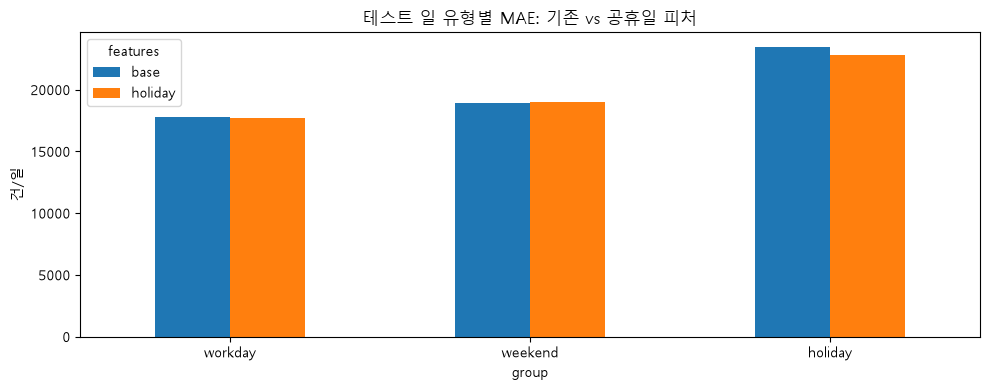

{'rule': 'adopt holiday feature if selected-model mean CV MAE decreases; test is report-only',
 'base_model': 'random_forest',
 'base_cv_MAE': np.float64(29886.893129104257),
 'holiday_model': 'random_forest',
 'holiday_cv_MAE': np.float64(29923.712894620632),
 'cv_change_pct': np.float64(0.12319703275052163),
 'adopt_holiday': False,
 'holiday_importance_MAE': 66.06179418230022,
 'test_MAE': {'base': 18370.258006201308, 'holiday': 18324.4446214108}}

In [4]:
# Report-only: test results never change the decision above.
predictions, models8 = {"lag_7": test8.lag_7.to_numpy()}, {}
for name, experiment in experiments.items():
    model8 = clone(experiment["search"].best_estimator_).fit(final_train8[experiment["columns"]], final_train8.rentals)
    models8[name] = model8
    predictions[name] = model8.predict(test8[experiment["columns"]])
test_scores8 = compare(test8, predictions)
test_scores8.to_csv(OUT / "08_test.csv")
display(test_scores8.round(4))
day_type = np.select([(test8.holiday == 1) & (test8.weekend == 0), test8.weekend == 1], ["holiday", "weekend"], "workday")
day_rows = []
for name in experiments:
    detail8 = test8[["date", "rentals"]].assign(prediction=predictions[name], day_type=day_type)
    day_rows.append(grouped_metrics(detail8, "day_type").assign(features=name).reset_index())
by_day = pd.concat(day_rows, ignore_index=True)
by_day.to_csv(OUT / "08_day_type.csv", index=False)
display(by_day.round(4))
by_day.pivot(index="group", columns="features", values="MAE").loc[["workday", "weekend", "holiday"]].plot.bar(
    title="테스트 일 유형별 MAE: 기존 vs 공휴일 피처", ylabel="건/일", rot=0)
plt.tight_layout()
plt.savefig(OUT / "08_day_type.png", dpi=120)
plt.show()
importance8 = permutation_importance(models8["holiday"], test8[HOLIDAY_FEATURES], test8.rentals,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=42, n_jobs=1)
decision["holiday_importance_MAE"] = float(importance8.importances_mean[HOLIDAY_FEATURES.index("holiday")])
decision["test_MAE"] = {name: float(test_scores8.loc[name, "MAE"]) for name in experiments}
(OUT / "08_decision.json").write_text(json.dumps(decision, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(decision)


- 테스트 MAE는 기존 18,370건, 공휴일 추가 18,324건으로 -0.25% 변함.
- 평일 공휴일 9일의 MAE는 23,461건에서 22,820건으로 변함.
- 테스트 순열 중요도에서 holiday의 MAE 증가는 66건임.
- 테스트 결과는 보고용이며 채택 여부와 설정 선택에 사용하지 않음.
- 평일 공휴일 표본이 적어 개선·악화를 일반화하기 어렵고 연휴 전후·공휴일 다음 주 lag_7 왜곡은 별도 피처로 다루지 않음.